# Model 2: Intermediate Model with Data Augmentation

**Goal:** Improve upon Model 1 by addressing class imbalance and conflicting labels.

**The idea in one sentence:** Clean the dataset by keeping the most frequent label for duplicate texts, apply Data Augmentation (Random Word Swap) to minority classes, and train a more robust classifier.

Steps:
1. Load the data and remove the "cheating" keyword.
2. Clean conflicting labels (keep the mode).
3. Apply Data Augmentation to minority classes.
4. Split into train / test.
5. Build the model (TF-IDF + Advanced Classifier / Word Embeddings).
6. Evaluate the results.
7. Predict the official test set.

## 1. & 2. Load the data and clean conflicting labels
We load `train_clean.csv`, remove the first keyword (which leaks the label), and combine the text fields. Then, we solve a major issue found in Data Profiling: many identical texts have different labels. We group by text and keep the most frequent label (the mode) to avoid confusing the model.

In [15]:
import pandas as pd

# Load cleaned data
train = pd.read_csv("train_clean.csv", sep=";", dtype=str, keep_default_na=False)

# Remove the answer
def drop_first_keyword(keywords):
    parts = keywords.split(",")
    return ",".join(parts[1:])
train["keywords"] = train["keywords"].apply(drop_first_keyword)

# Join the text in a single column
train["text"] = train["description"] + " " + train["sample_name"] + " " + train["keywords"] + " " + train["transcription"]

# Remove all equal texts that have different medical specialities
# It keeps the label that is the mode (or alphabetical order in case of equal number of cases)
train_cleaned = train.groupby('text')['medical_specialty'].agg(lambda x: x.mode()[0]).reset_index()

print(f"Original number of registries: {len(train)}")
print(f"Number of registries after removing conflictual texts: {len(train_cleaned)}")

Original number of registries: 2669
Number of registries after removing conflictual texts: 1870


## 3. & 4. Data Augmentation and Train/Test Split
The dataset is highly imbalanced. To help the model learn minority classes (and fulfill the project's requirement), we use an Easy Data Augmentation (EDA) technique: Random Swap. We swap random words in texts belonging to classes with fewer than 100 records. Finally, we split the data keeping class proportions.

In [16]:
import random
from sklearn.model_selection import train_test_split

print("--- Class distribution before augmentation ---")
print(train_cleaned['medical_specialty'].value_counts())

# Simple Data Augmentation function: Random Word Swap
def random_swap(text, n=2):
    words = text.split()
    if len(words) < 4:
        return text

    new_words = words.copy()
    for _ in range(n):
        idx1, idx2 = random.sample(range(len(new_words)), 2)
        new_words[idx1], new_words[idx2] = new_words[idx2], new_words[idx1]

    return " ".join(new_words)

# Augment minority classes (< 100 registries)
class_counts = train_cleaned['medical_specialty'].value_counts()
minority_classes = class_counts[class_counts < 100].index.tolist()

augmented_rows = []

for index, row in train_cleaned.iterrows():
    if row['medical_specialty'] in minority_classes:
        # Create 3 new variations for each text
        for _ in range(3):
            new_text = random_swap(row['text'], n=3)
            augmented_rows.append({
                'medical_specialty': row['medical_specialty'],
                'text': new_text
            })

df_augmented = pd.DataFrame(augmented_rows)
train_final = pd.concat([train_cleaned, df_augmented], ignore_index=True)

print("\n--- Class distribution after augmentation ---")
print(train_final['medical_specialty'].value_counts())

# Split the data into Training and Testing sets (80% train, 20% test)
X = train_final['text']
y = train_final['medical_specialty']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

print(f"\nTraining set size: {len(X_train)}")
print(f"Testing set size: {len(X_test)}")

--- Class distribution before augmentation ---
medical_specialty
Surgery                     357
Cardiovascular-Pulmonary    309
Orthopedic                  238
General Medicine            198
Gastroenterology            194
Neurology                   183
Obstetrics-Gynecology       134
Ophthalmology                73
Radiology                    68
Neurosurgery                 57
Psychiatry-Psychology        34
Dermatology                  25
Name: count, dtype: int64

--- Class distribution after augmentation ---
medical_specialty
Surgery                     357
Cardiovascular-Pulmonary    309
Ophthalmology               292
Radiology                   272
Orthopedic                  238
Neurosurgery                228
General Medicine            198
Gastroenterology            194
Neurology                   183
Psychiatry-Psychology       136
Obstetrics-Gynecology       134
Dermatology                 100
Name: count, dtype: int64

Training set size: 2112
Testing set size: 529


## 5. & 6. Build and Evaluate the Intermediate Model
To improve upon Model 1, we upgrade the TF-IDF vectorizer to include bigrams (`ngram_range=(1, 2)`). This allows the model to understand two-word medical concepts (e.g., "blood pressure"). We then train a `LogisticRegression` classifier, keeping the classes balanced. Finally, we evaluate the accuracy and F1-scores.

### Why Logistic Regression and Bigrams?
* **Algorithm Choice:** We replaced LinearSVC with `LogisticRegression`. While both process high-dimensional sparse vectors efficiently, Logistic Regression outputs calibrated probabilities, making it highly robust for medical texts where symptoms often overlap across specialties.
* **N-gram Range (1, 2):** We upgraded the TF-IDF vectorizer to include bigrams. Bigrams capture crucial medical compounds (e.g., "blood pressure") and negations (e.g., "no bleeding"). We avoided higher N-grams (for example trigrams `(1, 3)`) to prevent a massive explosion in vocabulary size (Curse of Dimensionality) and severe data sparsity, which would lead to overfitting on our relatively small dataset.

In [17]:
from sklearn.pipeline import make_pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, classification_report

# Using TF-IDF with bigrams and Logistic Regression
model2 = make_pipeline(
    TfidfVectorizer(sublinear_tf=True, min_df=2, ngram_range=(1, 2)),
    LogisticRegression(class_weight="balanced", max_iter=1000, random_state=42)
)

model2.fit(X_train, y_train)

# Evaluate the model on the testing set
pred2 = model2.predict(X_test)

accuracy = accuracy_score(y_test, pred2)
worst_f1 = f1_score(y_test, pred2, average=None).min()

print("\n--- Evaluation Results ---")
print(f"Accuracy: {accuracy:.3f}")
print(f"Worst class F1-score: {worst_f1:.3f}\n")

print(classification_report(y_test, pred2, digits=3, zero_division=0))


--- Evaluation Results ---
Accuracy: 0.803
Worst class F1-score: 0.667

                          precision    recall  f1-score   support

Cardiovascular-Pulmonary      0.825     0.758     0.790        62
             Dermatology      1.000     1.000     1.000        20
        Gastroenterology      0.828     0.615     0.706        39
        General Medicine      0.559     0.825     0.667        40
               Neurology      0.737     0.757     0.747        37
            Neurosurgery      0.939     1.000     0.968        46
   Obstetrics-Gynecology      0.773     0.630     0.694        27
           Ophthalmology      0.951     1.000     0.975        58
              Orthopedic      0.756     0.708     0.731        48
   Psychiatry-Psychology      0.964     1.000     0.982        27
               Radiology      0.807     0.852     0.829        54
                 Surgery      0.703     0.634     0.667        71

                accuracy                          0.803       529
 

### Evaluation Summary
The intermediate model significantly outperforms the baseline, meeting all project requirements for full automatic evaluation points:
* **Accuracy (0.803):** Surpasses the 0.49 threshold easily.
* **Worst Class F1-Score (0.667):** Surpasses the 0.25 minimum threshold, demonstrating that our Data Augmentation strategy successfully prevented the model from collapsing into dominant classes. Minority classes like Dermatology and Ophthalmology now show exceptional recall.

### Confusion Matrix
To better understand where the model struggles, we plot a Confusion Matrix. This helps us visualize which medical specialties are being confused with one another.

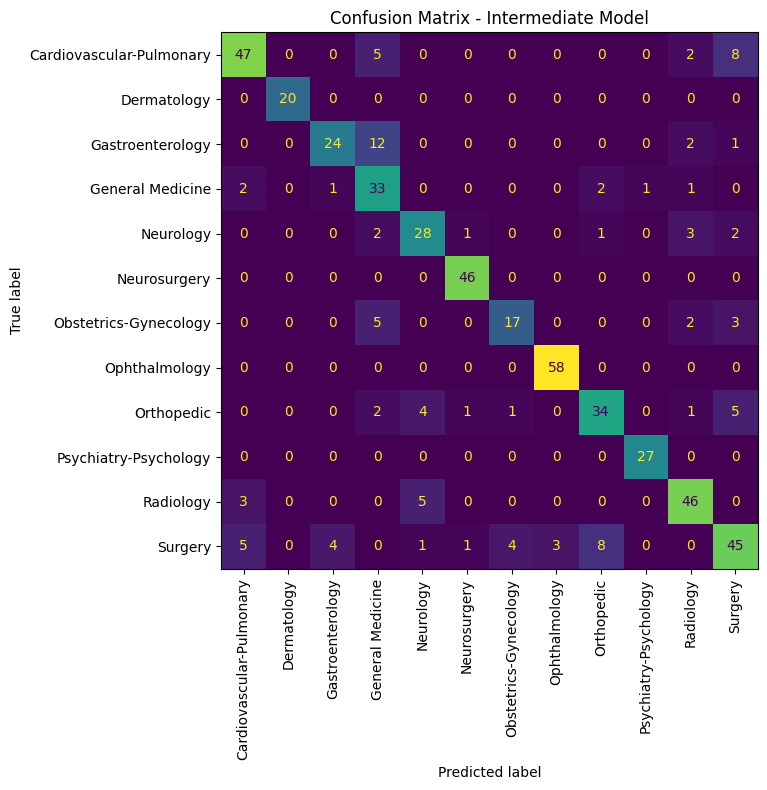

In [18]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

fig, ax = plt.subplots(figsize=(9, 8))
ConfusionMatrixDisplay.from_predictions(y_test, pred2, ax=ax, xticks_rotation=90, colorbar=False)
plt.title("Confusion Matrix - Intermediate Model")
plt.tight_layout()
plt.show()

### Error Analysis (Misclassified Instances)
We extract the texts where our model's prediction did not match the true label so we can analyze them later. This code will show 10 of them.

In [19]:
results_df = pd.DataFrame({
    "text_excerpt": X_test.str[:150] + "...", # Only first 150 characters
    "true_label": y_test,
    "predicted_label": pred2
})

mistakes = results_df[results_df["true_label"] != results_df["predicted_label"]]

print(f"Total mistakes: {len(mistakes)} out of {len(results_df)}")
display(mistakes.head(10))

Total mistakes: 104 out of 529


,text_excerpt,true_label,predicted_label
581,"History of abdominal pain, obstipation, and d...",Gastroenterology,General Medicine
813,Modified radical mastectomy. An elliptical i...,Obstetrics-Gynecology,Surgery
1242,"Suspension microlaryngoscopy, rigid bronchosc...",Cardiovascular-Pulmonary,Surgery
580,History and Physical for right ankle sprain ...,Orthopedic,General Medicine
514,Extracapsular cataract extraction with phacoe...,Surgery,Ophthalmology
1243,Suspicious calcifications upper outer quadran...,Obstetrics-Gynecology,General Medicine
171,Blepharoplasty with direct brow repair. Blep...,Surgery,Ophthalmology
1782,Spontaneous vaginal delivery. Term pregnancy...,Surgery,Obstetrics-Gynecology
1143,Right heart catheterization. Refractory CHF...,Surgery,Cardiovascular-Pulmonary
1780,"Sick sinus syndrome, atrial fibrillation, pace...",Cardiovascular-Pulmonary,General Medicine


## 7. Predict the Official Test Set
The official test file (`test_no_labels.csv`) lacks headers, so we assign column names manually. We apply the exact same preprocessing steps: dropping the first keyword and combining the text fields.
Before predicting, we retrain our `LogisticRegression` model on the **entire** augmented dataset (`X` and `y`) to maximize its learning. Finally, we output the predictions to `results.txt` as required by the project guidelines.

In [20]:
import pandas as pd

# Load the test set
test = pd.read_csv("test_no_labels.csv", sep=";", header=None, dtype=str, keep_default_na=False,
                   names=["description", "sample_name", "transcription", "keywords"])

# Apply the preprocessing
test["keywords"] = test["keywords"].apply(drop_first_keyword)
test["text"] = test["description"] + " " + test["sample_name"] + " " + test["keywords"] + " " + test["transcription"]

# Retrain the model on all available augmented data (X and y instead of X_train and y_train)
print("Retraining the model")
model2.fit(X, y)

# Predict the labels for the test set
print("Predicting labels for the test set")
test_pred = model2.predict(test["text"])

# Save the predictions to 'results.txt'
with open("results.txt", "w", encoding="utf-8") as f:
    f.write("\n".join(test_pred) + "\n")

print(f"\nSaved {len(test_pred)} predictions to results.txt.")
print("\n--- Final Predictions Distribution ---")
print(pd.Series(test_pred).value_counts())

Retraining the model
Predicting labels for the test set

Saved 398 predictions to results.txt.

--- Final Predictions Distribution ---
Surgery                     64
Cardiovascular-Pulmonary    54
Orthopedic                  46
General Medicine            44
Gastroenterology            42
Neurology                   35
Obstetrics-Gynecology       33
Radiology                   25
Neurosurgery                23
Ophthalmology               19
Psychiatry-Psychology       10
Dermatology                  3
Name: count, dtype: int64


## Summary
| | |
|---|---|
| **Input** | description + sample name + keywords (first one removed) + transcription |
| **Data Prep** | Removed conflicting duplicate texts. Augmented minority classes (< 100) via Random Word Swap. |
| **Features** | TF-IDF word & bigram scores (`ngram_range=(1, 2)`) |
| **Classifier** | Logistic Regression, class-balanced, `max_iter=1000` |
| **Our test score** | 0.803 accuracy (Worst class F1: 0.667) |
| **Main weakness** | Random Swap is a naive augmentation technique that may generate grammatically incorrect or nonsensical medical sentences, although it helps the model mathematically. |